<a href="https://colab.research.google.com/github/MichaelCM7/SemProject_MLEngine/blob/main/Model_Base.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Initialization and Installation of the dataset

In [ ]:
import os
from google.colab import files
from google.colab import userdata

# Use the Kaggle API Key and Kaggle Username in the secrets panel
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_API_KEY')

# Download the dataset from Kaggle and unzip the downloaded folder
!kaggle datasets download -d mexwell/crop-diseases-classification
!unzip -q crop-diseases-classification.zip -d ./dataset

Dataset URL: https://www.kaggle.com/datasets/mexwell/crop-diseases-classification
License(s): other
100% 2.00G/2.00G [00:53<00:00, 40.4MB/s]



#### Find the distribution of images after separating missing values

In [ ]:
import os
import json
import pandas as pd

# Dynamically build file index
print("Building image file index across dataset...")
image_path_map = {}
csv_path = None
json_path = None

for root, dirs, files in os.walk("./dataset"):
    if 'train.csv' in files:
        csv_path = os.path.join(root, 'train.csv')
    if 'label_num_to_disease_map.json' in files:
        json_path = os.path.join(root, 'label_num_to_disease_map.json')
    for f in files:
        if f.endswith('.jpg') or f.endswith('.png'):
            image_path_map[f] = os.path.join(root, f)

# Load ground truth CSV & Label Mapping
df = pd.read_csv(csv_path)
with open(json_path, 'r') as f:
    label_map = json.load(f)

# Helper to verify image file existence
def exists(img_id):
    name = str(img_id).strip()
    return (name in image_path_map) or (f"{name}.jpg" in image_path_map)

# Audit missing images
df['file_exists'] = df['image_id'].apply(exists)
missing_df = df[~df['file_exists']]
valid_df = df[df['file_exists']].copy()

print(f"\n--- DATASET AUDIT RESULTS ---")
print(f"Total entries in CSV: {len(df)}")
print(f"Valid images found:   {len(valid_df)}")
print(f"Missing images:       {len(missing_df)}")

if len(missing_df) > 0:
    print(f"\nSample of missing images:")
    print(missing_df[['image_id', 'label']].head())

# Evaluate class distribution of existing images
valid_df['disease_name'] = valid_df['label'].astype(str).map(label_map)

print(f"\n--- CLASS DISTRIBUTION (FILTERED DATASET) ---")
distribution = valid_df['disease_name'].value_counts()
print(distribution.to_string())

# Export filtered CSV for Block 2 if needed
filtered_csv_path = "./dataset/filtered_train.csv"
valid_df.to_csv(filtered_csv_path, index=False)
print(f"\nSaved filtered dataset index to: {filtered_csv_path}")

Building image file index across dataset...

--- DATASET AUDIT RESULTS ---
Total entries in CSV: 21397
Valid images found:   17938
Missing images:       3459

Sample of missing images:
         image_id  label
0  1000015157.jpg      0
1  1000201771.jpg      3
2   100042118.jpg      1
3  1000723321.jpg      1
4  1000812911.jpg      3

--- CLASS DISTRIBUTION (FILTERED DATASET) ---
disease_name
Cassava Mosaic Disease (CMD)           11027
Healthy                                 2166
Cassava Green Mottle (CGM)              1993
Cassava Brown Streak Disease (CBSD)     1831
Cassava Bacterial Blight (CBB)           921

Saved filtered dataset index to: ./dataset/filtered_train.csv


#### Training and Evaluation

In [ ]:
import json
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader, random_split, WeightedRandomSampler
from torchvision import transforms
from sklearn.metrics import classification_report

# Enable fast TF32 matrix multiplication and cuDNN autotuning
torch.set_float32_matmul_precision('high')
torch.backends.cudnn.benchmark = True

# Define Graphing Variables
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# 1. Dataset Class
class FilteredCropDataset(Dataset):
    def __init__(self, df, json_path, img_map, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_map = img_map
        self.transform = transform

        with open(json_path, 'r') as f:
            self.label_map = json.load(f)

        self.classes = [self.label_map[str(i)] for i in sorted(map(int, self.label_map.keys()))]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_name = str(row['image_id']).strip()

        img_path = self.img_map.get(img_name, self.img_map.get(f"{img_name}.jpg"))

        image = Image.open(img_path).convert('RGB')
        label = int(row['label'])

        if self.transform:
            image = self.transform(image)

        return image, label

# 2. Optimized 224x224 Transforms
img_size = 224
batch_size = 64

train_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomCrop(img_size, padding=8, padding_mode='edge'),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_dataset_full = FilteredCropDataset(valid_df, json_path, image_path_map, transform=train_transform)
val_dataset_full = FilteredCropDataset(valid_df, json_path, image_path_map, transform=val_transform)

train_size = int(0.8 * len(train_dataset_full))
val_size = len(train_dataset_full) - train_size

generator = torch.Generator().manual_seed(42)
train_dataset, _ = random_split(train_dataset_full, [train_size, val_size], generator=generator)
_, val_dataset = random_split(val_dataset_full, [train_size, val_size], generator=generator)

# --- Mild Smoothed Sampler ---
train_indices = train_dataset.indices
train_targets = [int(train_dataset_full.df.iloc[idx]['label']) for idx in train_indices]

class_counts = torch.bincount(torch.tensor(train_targets))
class_weights_sampler = 1.0 / (class_counts.float() ** 0.5)
sample_weights = [class_weights_sampler[t] for t in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=sampler,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

# 3. Depthwise Separable Conv + Squeeze-and-Excitation Module
class SEDSConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(SEDSConvBlock, self).__init__()
        self.conv = nn.Sequential(
            # Depthwise Convolution
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1, groups=in_channels, bias=False),
            nn.BatchNorm2d(in_channels),
            nn.SiLU(),

            # Pointwise Convolution
            nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.SiLU()
        )

        # Squeeze-and-Excitation Attention
        self.se = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(out_channels, max(1, out_channels // 4), kernel_size=1),
            nn.SiLU(),
            nn.Conv2d(max(1, out_channels // 4), out_channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv(x)
        weight = self.se(x)
        return x * weight

# 4. Optimized Architecture with GAP
class FullyOptimizedCropCNN(nn.Module):
    def __init__(self, num_classes):
        super(FullyOptimizedCropCNN, self).__init__()
        self.features = nn.Sequential(
            # Stem: Initial convolution (224x224 -> 112x112)
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.MaxPool2d(2, 2),

            # Block 1: 112x112 -> 56x56
            SEDSConvBlock(32, 64),
            nn.MaxPool2d(2, 2),

            # Block 2: 56x56 -> 28x28
            SEDSConvBlock(64, 128),
            nn.MaxPool2d(2, 2),

            # Block 3: 28x28 -> 14x14
            SEDSConvBlock(128, 256),
            nn.MaxPool2d(2, 2),

            # Block 4: 14x14 -> 1x1
            SEDSConvBlock(256, 256),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

num_classes = len(train_dataset_full.classes)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate model and transfer to GPU using channels_last memory layout
model = FullyOptimizedCropCNN(num_classes).to(device, memory_format=torch.channels_last)

# Optional Kernel Fusion via PyTorch 2.x compile
try:
    model = torch.compile(model)
    print("✓ Model compiled with torch.compile()")
except Exception as e:
    print("Running standard PyTorch execution without compilation")

# Label smoothing prevents overconfidence
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)

epochs = 45
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=3.5e-3,
    steps_per_epoch=len(train_loader),
    epochs=epochs,
    pct_start=0.3
)

scaler = torch.amp.GradScaler('cuda')

# 5. Fast Training Loop
best_val_acc = 0.0

print(f"Starting training on {device} for {epochs} epochs at 224x224 resolution...\n")

for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    train_correct_count = 0

    for inputs, labels in train_loader:
        # Load tensors using channels_last layout for GPU acceleration
        inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Fast zeroing out without allocation overhead
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()

        # Gradient Clipping for Training Stability
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        scheduler.step()

        running_train_loss += loss.item() * inputs.size(0)
        train_correct_count += (outputs.argmax(1) == labels).sum().item()

    # Calculate training epoch metrics
    epoch_train_loss = running_train_loss / train_size
    train_acc = train_correct_count / train_size

    model.eval()
    running_val_loss = 0.0
    val_correct_count = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, memory_format=torch.channels_last, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            val_correct_count += (outputs.argmax(1) == labels).sum().item()

    # Calculate validation epoch metrics
    epoch_val_loss = running_val_loss / val_size
    val_acc = val_correct_count / val_size

    # Append metrics to global lists for graphing
    train_losses.append(epoch_train_loss)
    test_losses.append(epoch_val_loss)
    train_correct.append(train_acc)
    test_correct.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_crop_model.pth")
        saved_flag = " (Model Saved)"
    else:
        saved_flag = ""

    print(f"Epoch {epoch+1:02d}/{epochs} | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Train Acc: {train_acc:.4f} | "
          f"Val Acc: {val_acc:.4f}{saved_flag}")

print(f"\nTraining Complete! Best Validation Accuracy: {best_val_acc:.4f}\n")

# 6. Classification Report
print("--- PER-CLASS PERFORMANCE ANALYSIS ---")
model.load_state_dict(torch.load("best_crop_model.pth"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device, memory_format=torch.channels_last)
        with torch.amp.autocast('cuda'):
            outputs = model(inputs)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=train_dataset_full.classes))

✓ Model compiled with torch.compile()
Starting training on cuda for 45 epochs at 224x224 resolution...



W1029 08:11:46.234000 869 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Epoch 01/45 | Train Loss: 1.4625 | Val Loss: 1.1346 | Train Acc: 0.3994 | Val Acc: 0.6382 (Model Saved)
Epoch 02/45 | Train Loss: 1.3198 | Val Loss: 1.0778 | Train Acc: 0.4764 | Val Acc: 0.6608 (Model Saved)
Epoch 03/45 | Train Loss: 1.2603 | Val Loss: 1.0910 | Train Acc: 0.5209 | Val Acc: 0.6410
Epoch 04/45 | Train Loss: 1.1874 | Val Loss: 1.0737 | Train Acc: 0.5661 | Val Acc: 0.6455
Epoch 05/45 | Train Loss: 1.1359 | Val Loss: 0.9176 | Train Acc: 0.6042 | Val Acc: 0.7274 (Model Saved)
Epoch 06/45 | Train Loss: 1.0893 | Val Loss: 0.9924 | Train Acc: 0.6311 | Val Acc: 0.6959
Epoch 07/45 | Train Loss: 1.0308 | Val Loss: 0.9361 | Train Acc: 0.6655 | Val Acc: 0.7288 (Model Saved)
Epoch 08/45 | Train Loss: 1.0169 | Val Loss: 0.8586 | Train Acc: 0.6790 | Val Acc: 0.7614 (Model Saved)
Epoch 09/45 | Train Loss: 0.9866 | Val Loss: 0.9605 | Train Acc: 0.6962 | Val Acc: 0.7163
Epoch 10/45 | Train Loss: 0.9655 | Val Loss: 0.8229 | Train Acc: 0.7063 | Val Acc: 0.7848 (Model Saved)
Epoch 11/45 | Tr

### Plot Results

In [ ]:
!pip install matplotlib -q

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline


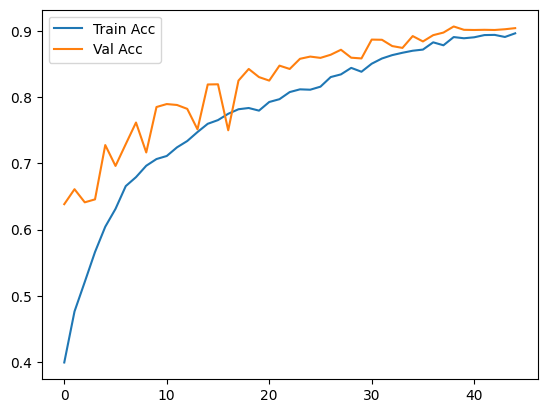

In [ ]:
# Plot Training vs Validation Accuracy
plt.plot(train_correct, label='Train Acc')
plt.plot(test_correct, label='Val Acc')
plt.legend()
plt.show()

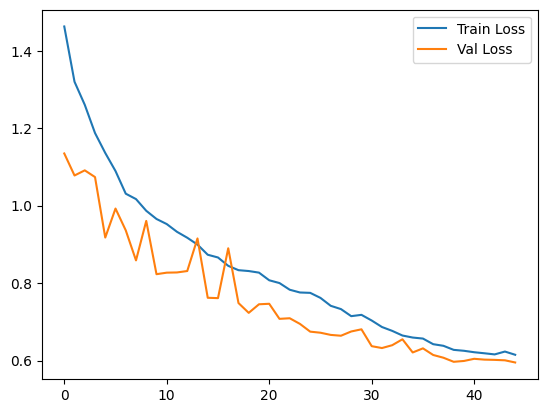

In [ ]:
# Plot Training vs Validation Loss
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Val Loss')
plt.legend()
plt.show()

### Manual Test

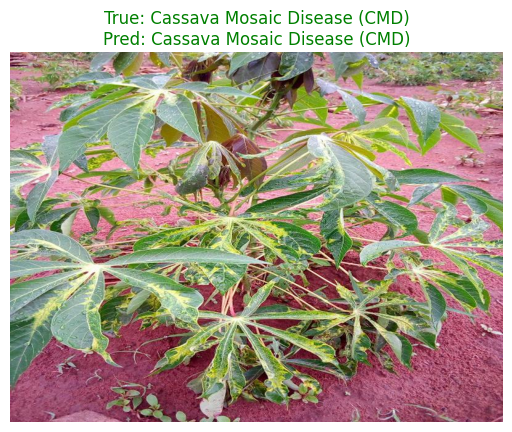

In [ ]:
import random

# 1. Pick a random test image
idx = random.randint(0, len(val_dataset_full) - 1)
img_tensor, true_idx = val_dataset_full[idx]

# 2. Get Model Prediction
model.eval()
with torch.no_grad():
    input_batch = img_tensor.unsqueeze(0).to(device)
    outputs = model(input_batch)
    pred_idx = outputs.argmax(1).item()

# 3. Get Class Names
true_name = train_dataset_full.classes[true_idx]
pred_name = train_dataset_full.classes[pred_idx]

# 4. Display Image and Result
img_path = val_dataset_full.img_map.get(str(val_dataset_full.df.iloc[idx]['image_id']).strip())
plt.imshow(Image.open(img_path))
plt.title(f"True: {true_name}\nPred: {pred_name}", color=('green' if true_idx == pred_idx else 'red'))
plt.axis('off')
plt.show()

Export Model WIth ONNX

In [ ]:
!pip install onnx onnxscript -q

import torch
from google.colab import files

# 1. Unwrap Dynamo/torch.compile wrapper if it exists
raw_model = model._orig_mod if hasattr(model, '_orig_mod') else model

# 2. Move unwrapped model to CPU and restore contiguous layout
raw_model = raw_model.to(device='cpu', memory_format=torch.contiguous_format)
raw_model.eval()

# 3. Create dummy input on CPU (224x224)
dummy_input = torch.randn(1, 3, 224, 224)
onnx_filename = "crop_disease_model.onnx"
labels_filename = "labels.txt"

# 4. Export safely using the raw, un-compiled model
torch.onnx.export(
    raw_model,
    dummy_input,
    onnx_filename,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=['input'],
    output_names=['output'],
    dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}},
    dynamo=False
)

print("✓ ONNX model exported cleanly!")

# 5. Save class labels file
classes = train_dataset_full.classes

with open(labels_filename, 'w') as f:
    for cls in classes:
        f.write(f"{cls}\n")

print("\nKotlin Class Labels saved to labels.txt:")
for idx, cls_name in enumerate(classes):
    print(f"  Index {idx}: {cls_name}")

# 6. Download files to local machine
files.download(onnx_filename)
files.download(labels_filename)

/tmp/ipykernel_869/2812066193.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✓ ONNX model exported cleanly!

Kotlin Class Labels saved to labels.txt:
  Index 0: Cassava Bacterial Blight (CBB)
  Index 1: Cassava Brown Streak Disease (CBSD)
  Index 2: Cassava Green Mottle (CGM)
  Index 3: Cassava Mosaic Disease (CMD)
  Index 4: Healthy


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>